# Ablation study

This small jupyter notebook is used to draw the figures for the ablation study, where we evaluate the performance of the XGBoost with several threhold to construct the labels.

## 1 Loading the data

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = Path("../resources/baselines/XGBoost")
P0_REF = 1e-4      # p0 used in the paper
N_BOOT = 1000
rng = np.random.default_rng(0)

rows = []
for d in ROOT.glob("ablation_study_p0_*"):
    p0 = float(re.search(r"p0_(.+)$", d.name).group(1))
    df = pd.read_csv(d / "test_predictions.csv")
    y, s = df["label"].to_numpy(), df["proba"].to_numpy()
    boot = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            boot.append(roc_auc_score(y[i], s[i]))
    rows.append(dict(p0=p0, auc=np.mean(boot),
                     lo=np.percentile(boot, 2.5), hi=np.percentile(boot, 97.5),
                     prevalence=y.mean()))

res = pd.DataFrame(rows).sort_values("p0").reset_index(drop=True)
res

,p0,auc,lo,hi,prevalence
0,0.00000,0.852722,0.833923,0.869947,0.051440
1,0.00001,0.855612,0.837926,0.872419,0.051440
2,0.00005,0.852195,0.835165,0.869475,0.050649
3,0.00010,0.848174,0.830816,0.866401,0.049066
4,0.00050,0.810477,0.787949,0.832375,0.035138
5,0.00100,0.798743,0.770751,0.825136,0.026432
6,0.00500,0.752405,0.706538,0.794248,0.010921


## Plotting the results

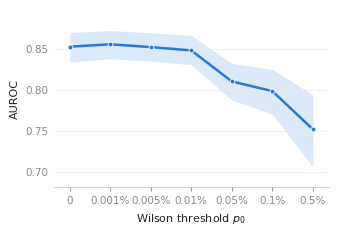

In [4]:
ACCENT = "#2a78d6"
INK, GREY, LIGHT, GRID = "#1f1f1e", "#8a8984", "#c9c8c2", "#ecebe7"

PAPER_STYLE = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.6, "axes.labelcolor": INK,
    "xtick.color": GREY, "ytick.color": GREY, "text.color": INK,
    "xtick.major.width": 0.6, "xtick.major.size": 3, "ytick.major.size": 0, "xtick.minor.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "pdf.fonttype": 42, "svg.fonttype": "none",
}

def plot_p0_sensitivity(res, p0_ref=P0_REF, path=None, figsize=(3.4, 2.4)):
    """Test AUROC (95% bootstrap CI) for each evaluated Wilson threshold p0."""
    res = res.sort_values("p0").reset_index(drop=True)
    x = np.arange(len(res))
    labels = ["0" if p == 0 else f"{100*p:g}%" for p in res.p0]

    with plt.rc_context(PAPER_STYLE):
        fig, ax = plt.subplots(figsize=figsize)
        ax.fill_between(x, res.lo, res.hi, color=ACCENT, alpha=0.16, lw=0, zorder=1)
        ax.plot(x, res.auc, color=ACCENT, lw=1.8, zorder=4,
                marker="o", ms=3.5, mfc=ACCENT, mec="white", mew=0.6)

        # ref = np.flatnonzero(np.isclose(res.p0, p0_ref))
        # if ref.size:
        #    ax.axvline(ref[0], color=GREY, ls=(0, (1, 2)), lw=0.8, zorder=0)

        ax.set_xticks(x, labels)
        ax.set_xlim(-0.4, len(res) - 0.6)
        ax.grid(axis="y", color=GRID, lw=0.6, zorder=0)
        ax.margins(y=0.15)
        ax.set_xlabel("Wilson threshold $p_0$")
        ax.set_ylabel("AUROC")
        fig.tight_layout()
        if path:
            fig.savefig(f"{path}.pdf", bbox_inches="tight")
            fig.savefig(f"{path}.png", dpi=800, bbox_inches="tight")
    return fig

plot_p0_sensitivity(res=res, path="ablation_p0")